# Temporal Analysis of Water Quality Data

**Objective:** Determine the optimal temporal granularity for Landsat image collection by analyzing:
1. Distribution of sampling timestamps
2. Temporal variability in water quality parameters per location
3. Intra-annual vs inter-annual changes

**Key Question:** Is one Landsat image per year sufficient, or do we need multiple images per year?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Configure display
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

## 1. Load and Prepare Data

In [2]:
# Load data
df = pd.read_csv('DATA/water_quality_training_dataset.csv')

# Parse dates
df['Date'] = pd.to_datetime(df['Sample Date'], format='%d-%m-%Y')

# Extract temporal features
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Quarter'] = df['Date'].dt.quarter
df['DayOfYear'] = df['Date'].dt.dayofyear
df['Season'] = df['Month'].map({12: 'Summer', 1: 'Summer', 2: 'Summer',
                                 3: 'Autumn', 4: 'Autumn', 5: 'Autumn',
                                 6: 'Winter', 7: 'Winter', 8: 'Winter',
                                 9: 'Spring', 10: 'Spring', 11: 'Spring'})

# Create location identifier
df['Location'] = df['Latitude'].round(3).astype(str) + ',' + df['Longitude'].round(3).astype(str)

print(f"Dataset shape: {df.shape}")
print(f"Date range: {df['Date'].min()} to {df['Date'].max()}")
print(f"Unique locations: {df['Location'].nunique()}")
print(f"Unique dates: {df['Date'].nunique()}")
print(f"\nWater quality parameters:")
print(df.columns.tolist())

Dataset shape: (9319, 13)
Date range: 2011-01-02 00:00:00 to 2015-12-31 00:00:00
Unique locations: 162
Unique dates: 1364

Water quality parameters:
['Latitude', 'Longitude', 'Sample Date', 'Total Alkalinity', 'Electrical Conductance', 'Dissolved Reactive Phosphorus', 'Date', 'Year', 'Month', 'Quarter', 'DayOfYear', 'Season', 'Location']


## 2. Temporal Distribution of Samples

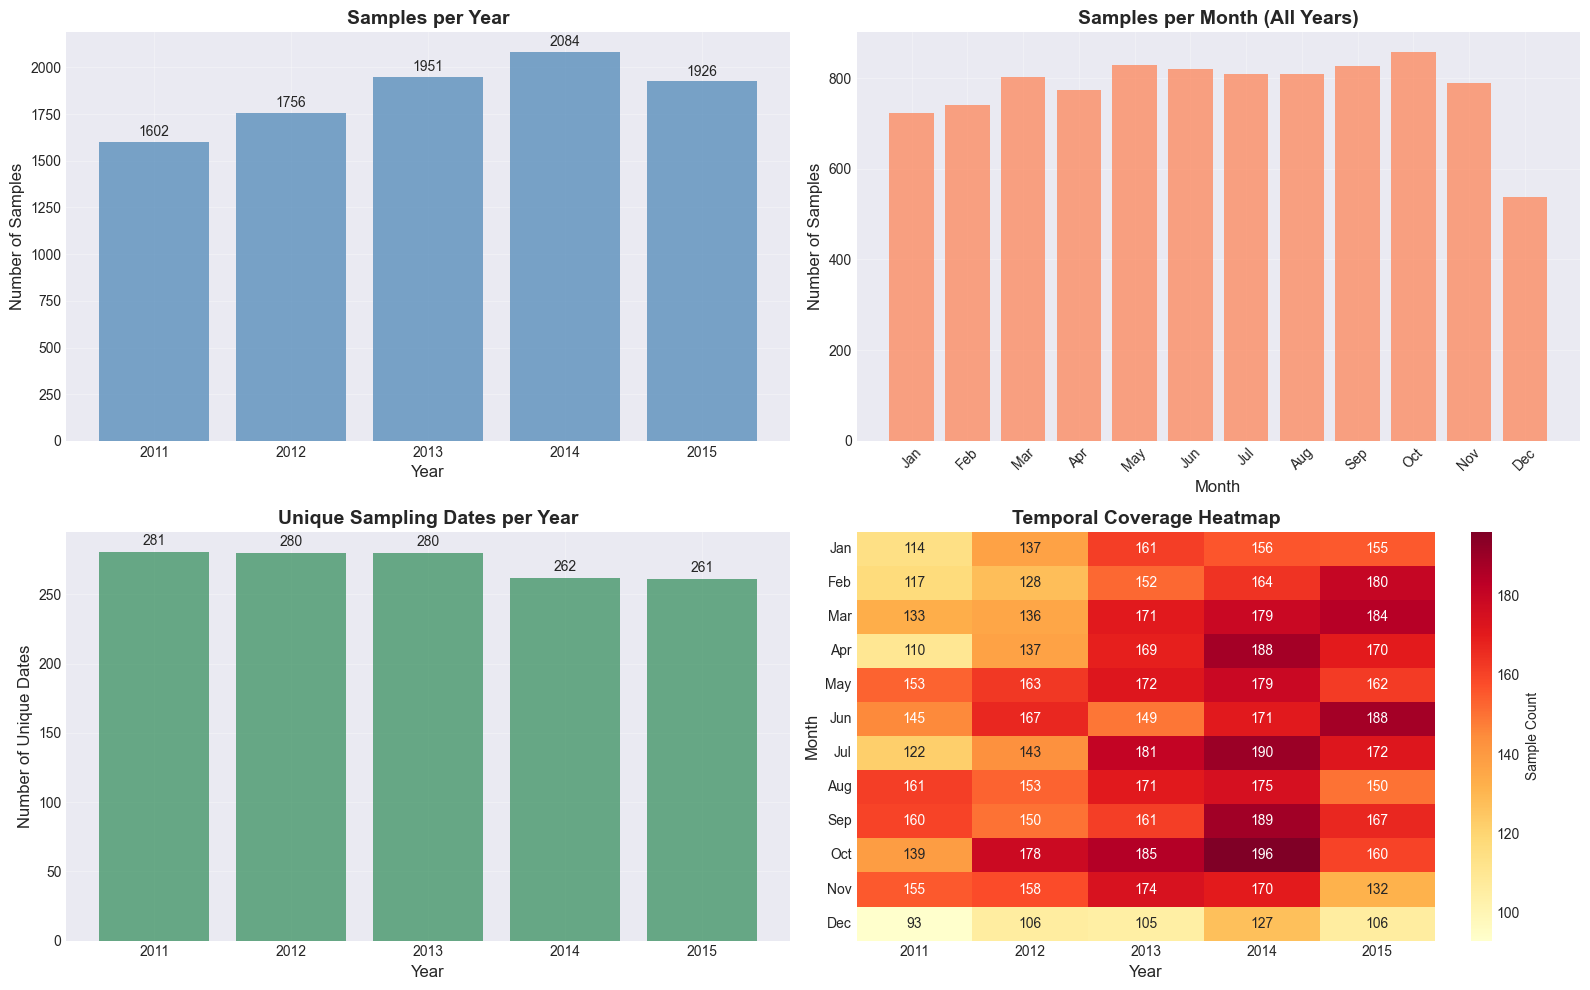

Average samples per year: 1863.8
Average unique dates per year: 272.8
Average samples per unique date: 6.8


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 2.1 Samples per year
yearly_counts = df['Year'].value_counts().sort_index()
axes[0, 0].bar(yearly_counts.index, yearly_counts.values, color='steelblue', alpha=0.7)
axes[0, 0].set_xlabel('Year', fontsize=12)
axes[0, 0].set_ylabel('Number of Samples', fontsize=12)
axes[0, 0].set_title('Samples per Year', fontsize=14, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)

# Add value labels
for i, v in enumerate(yearly_counts.values):
    axes[0, 0].text(yearly_counts.index[i], v + 30, str(v), ha='center', fontsize=10)

# 2.2 Samples per month (aggregated)
monthly_counts = df['Month'].value_counts().sort_index()
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
axes[0, 1].bar(range(1, 13), [monthly_counts.get(i, 0) for i in range(1, 13)], color='coral', alpha=0.7)
axes[0, 1].set_xlabel('Month', fontsize=12)
axes[0, 1].set_ylabel('Number of Samples', fontsize=12)
axes[0, 1].set_title('Samples per Month (All Years)', fontsize=14, fontweight='bold')
axes[0, 1].set_xticks(range(1, 13))
axes[0, 1].set_xticklabels(month_names, rotation=45)
axes[0, 1].grid(True, alpha=0.3)

# 2.3 Unique dates per year
unique_dates_per_year = df.groupby('Year')['Date'].nunique()
axes[1, 0].bar(unique_dates_per_year.index, unique_dates_per_year.values, color='seagreen', alpha=0.7)
axes[1, 0].set_xlabel('Year', fontsize=12)
axes[1, 0].set_ylabel('Number of Unique Dates', fontsize=12)
axes[1, 0].set_title('Unique Sampling Dates per Year', fontsize=14, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# Add value labels
for i, v in enumerate(unique_dates_per_year.values):
    axes[1, 0].text(unique_dates_per_year.index[i], v + 5, str(v), ha='center', fontsize=10)

# 2.4 Temporal coverage heatmap
temporal_matrix = df.groupby(['Year', 'Month']).size().unstack(fill_value=0)
sns.heatmap(temporal_matrix.T, annot=True, fmt='d', cmap='YlOrRd', ax=axes[1, 1], cbar_kws={'label': 'Sample Count'})
axes[1, 1].set_xlabel('Year', fontsize=12)
axes[1, 1].set_ylabel('Month', fontsize=12)
axes[1, 1].set_title('Temporal Coverage Heatmap', fontsize=14, fontweight='bold')
axes[1, 1].set_yticklabels(month_names, rotation=0)

plt.tight_layout()
plt.savefig('temporal_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Average samples per year: {yearly_counts.mean():.1f}")
print(f"Average unique dates per year: {unique_dates_per_year.mean():.1f}")
print(f"Average samples per unique date: {len(df) / df['Date'].nunique():.1f}")

## 3. Water Quality Temporal Variability Analysis

In [4]:
# Get water quality parameter columns
quality_params = ['Total Alkalinity', 'Electrical Conductance', 'Dissolved Reactive Phosphorus']

# Check which parameters exist
available_params = [col for col in quality_params if col in df.columns]
print(f"Available water quality parameters: {available_params}")

# Basic statistics
print("\nWater Quality Statistics:")
print(df[available_params].describe())

Available water quality parameters: ['Total Alkalinity', 'Electrical Conductance', 'Dissolved Reactive Phosphorus']

Water Quality Statistics:
       Total Alkalinity  Electrical Conductance  Dissolved Reactive Phosphorus
count       9319.000000             9319.000000                    9319.000000
mean         119.108208              485.004146                      43.525338
std           74.692591              341.937736                      50.980194
min            4.800000               15.120000                       5.000000
25%           55.811000              207.050000                      10.000000
50%          113.300000              402.000000                      20.000000
75%          170.230000              693.000000                      48.000000
max          361.676000             1506.000000                     195.000000


### 3.1 Temporal Trends - All Locations

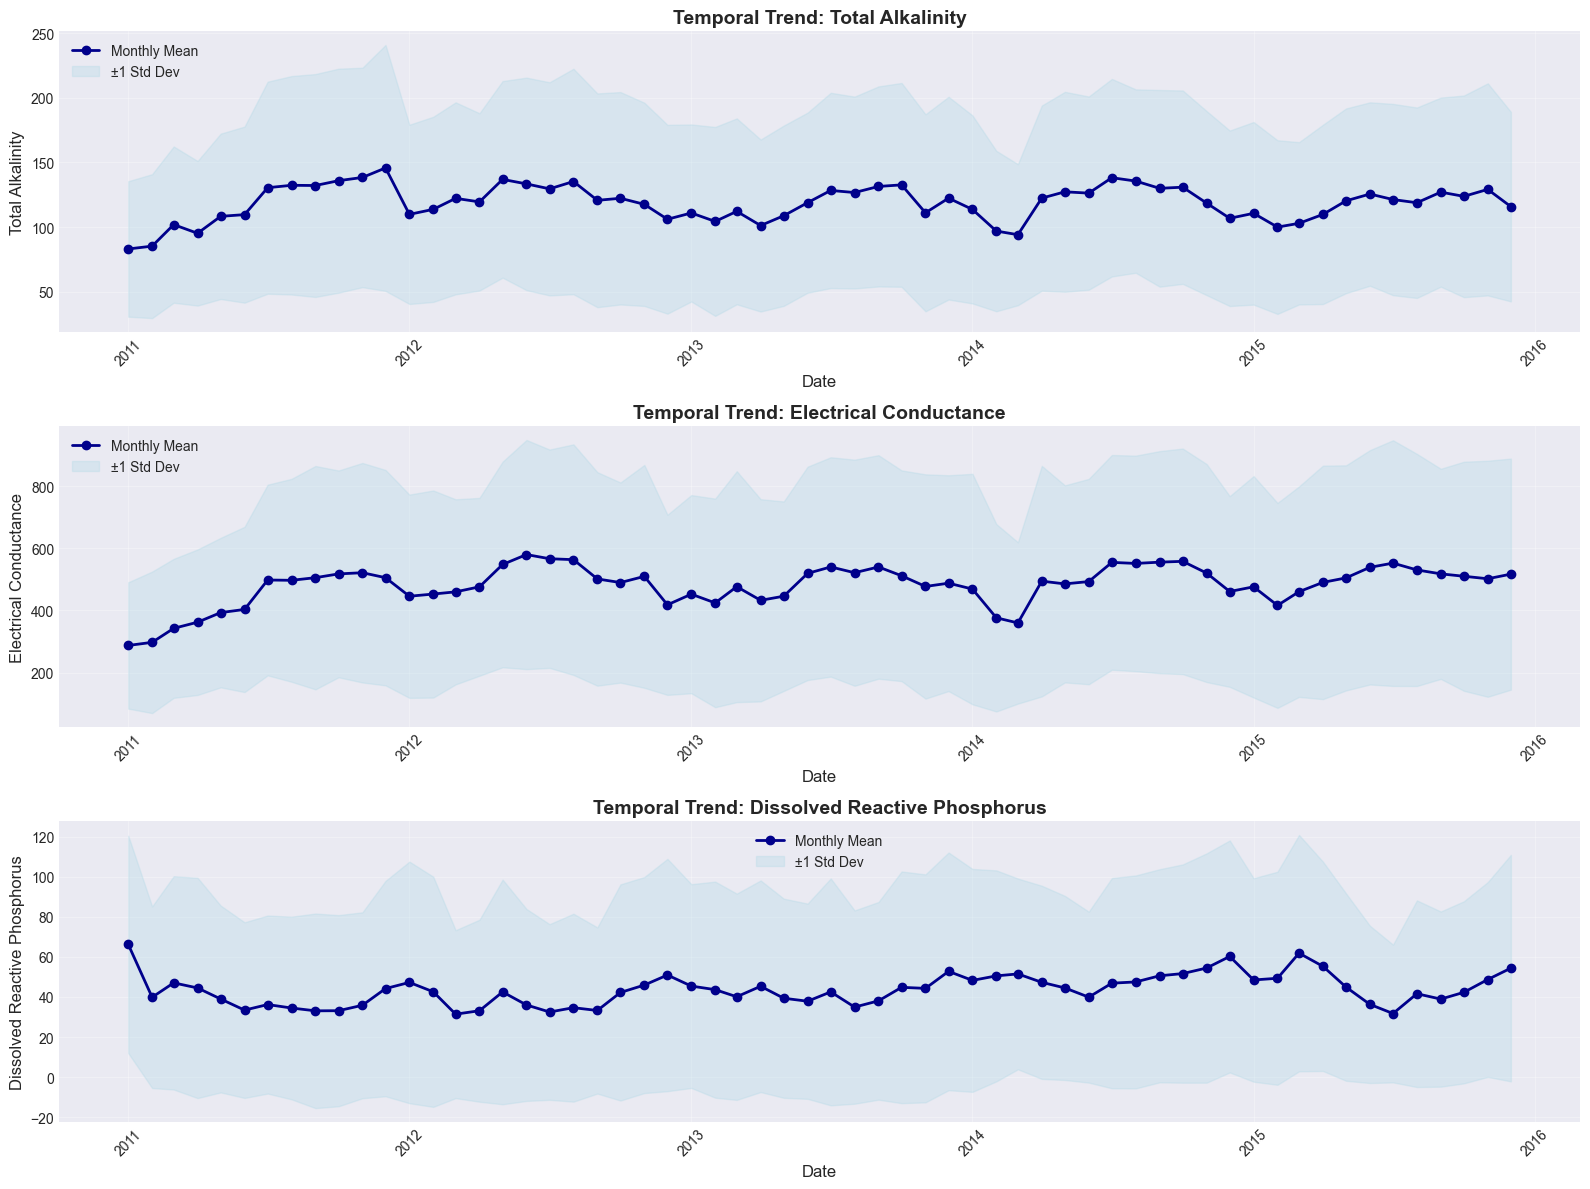

In [5]:
fig, axes = plt.subplots(len(available_params), 1, figsize=(16, 4 * len(available_params)))

if len(available_params) == 1:
    axes = [axes]

for idx, param in enumerate(available_params):
    # Monthly average with confidence interval
    monthly_data = df.groupby(['Year', 'Month'])[param].agg(['mean', 'std', 'count']).reset_index()
    monthly_data['date'] = pd.to_datetime(monthly_data['Year'].astype(str) + '-' + 
                                          monthly_data['Month'].astype(str) + '-01')
    monthly_data = monthly_data.sort_values('date')
    
    # Plot mean
    axes[idx].plot(monthly_data['date'], monthly_data['mean'], marker='o', 
                   linewidth=2, markersize=6, label='Monthly Mean', color='darkblue')
    
    # Add confidence interval
    axes[idx].fill_between(monthly_data['date'], 
                           monthly_data['mean'] - monthly_data['std'],
                           monthly_data['mean'] + monthly_data['std'],
                           alpha=0.3, color='lightblue', label='±1 Std Dev')
    
    axes[idx].set_xlabel('Date', fontsize=12)
    axes[idx].set_ylabel(param, fontsize=12)
    axes[idx].set_title(f'Temporal Trend: {param}', fontsize=14, fontweight='bold')
    axes[idx].legend(loc='best')
    axes[idx].grid(True, alpha=0.3)
    axes[idx].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('temporal_trends.png', dpi=300, bbox_inches='tight')
plt.show()

### 3.2 Seasonal Patterns

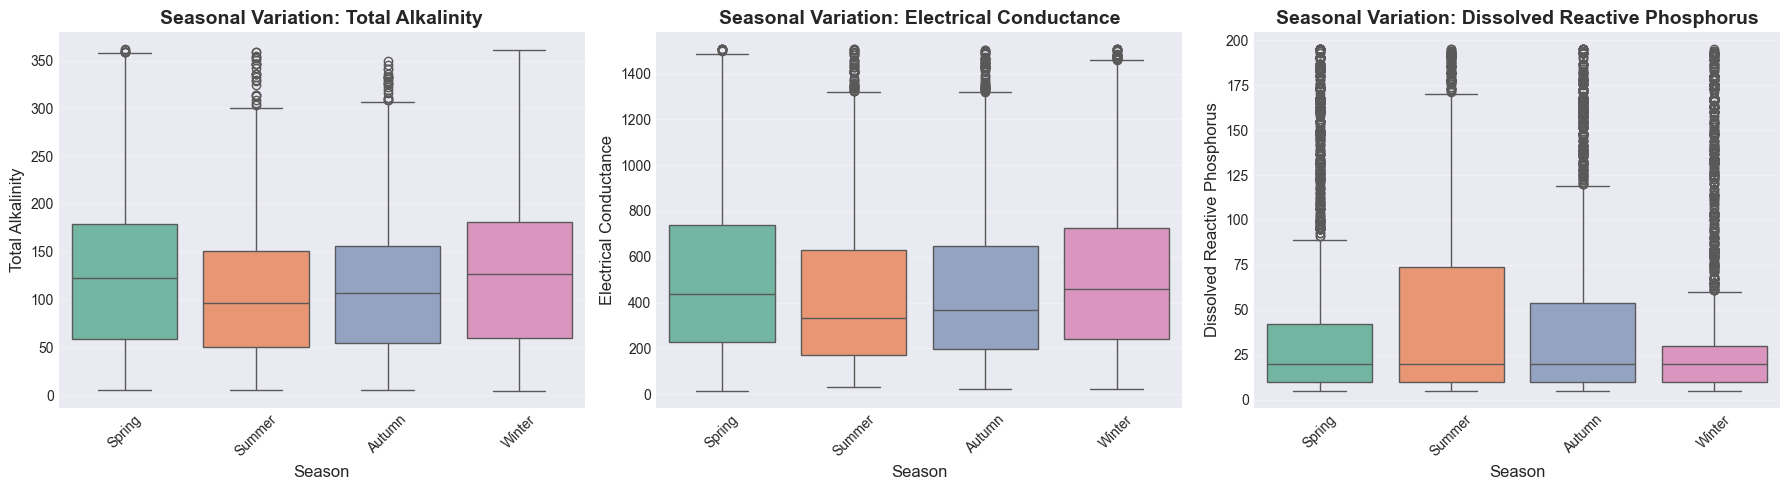


Seasonal Variability (Coefficient of Variation):

Total Alkalinity:
              mean        std         CV
Season                                  
Autumn  112.465277  69.007117  61.358597
Spring  126.650907  79.176886  62.515846
Summer  107.446218  70.916520  66.001876
Winter  127.581503  76.539867  59.992919

Electrical Conductance:
              mean         std         CV
Season                                   
Autumn  452.194039  321.839156  71.172799
Spring  516.799934  352.577788  68.223265
Summer  431.452624  327.497607  75.905810
Winter  529.070977  352.532401  66.632345

Dissolved Reactive Phosphorus:
             mean        std          CV
Season                                  
Autumn  44.995844  50.769133  112.830717
Spring  42.832441  51.411781  120.030006
Summer  49.345077  54.711591  110.875480
Winter  38.000684  46.839129  123.258649


In [6]:
fig, axes = plt.subplots(1, len(available_params), figsize=(6 * len(available_params), 5))

if len(available_params) == 1:
    axes = [axes]

season_order = ['Spring', 'Summer', 'Autumn', 'Winter']

for idx, param in enumerate(available_params):
    sns.boxplot(data=df, x='Season', y=param, order=season_order, ax=axes[idx], palette='Set2')
    axes[idx].set_title(f'Seasonal Variation: {param}', fontsize=14, fontweight='bold')
    axes[idx].set_xlabel('Season', fontsize=12)
    axes[idx].set_ylabel(param, fontsize=12)
    axes[idx].tick_params(axis='x', rotation=45)
    axes[idx].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('seasonal_patterns.png', dpi=300, bbox_inches='tight')
plt.show()

# Calculate seasonal variability
print("\nSeasonal Variability (Coefficient of Variation):")
for param in available_params:
    seasonal_cv = df.groupby('Season')[param].agg(['mean', 'std'])
    seasonal_cv['CV'] = (seasonal_cv['std'] / seasonal_cv['mean']) * 100
    print(f"\n{param}:")
    print(seasonal_cv)

### Visual Example of Intra vs Inter-Annual Variability

```
Example Dataset:
Year 2011: Jan=100, Apr=150, Jul=200, Oct=160  → Average=152.5, Std=41.5
Year 2012: Jan=105, Apr=155, Jul=210, Oct=165  → Average=158.8, Std=43.5
Year 2013: Jan=110, Apr=160, Jul=220, Oct=170  → Average=165.0, Std=45.3

INTRA-ANNUAL (within-year seasonal variation):
  → Average of the yearly standard deviations
  → (41.5 + 43.5 + 45.3) / 3 = 43.4
  → Measures: How much does water quality change from season to season?

INTER-ANNUAL (between-year trend):
  → Standard deviation of yearly averages
  → Std of [152.5, 158.8, 165.0] = 6.3
  → Measures: How much do year-to-year averages differ?

RATIO = Intra/Inter = 43.4 / 6.3 = 6.9
  → Seasonal changes (within year) are 6.9x larger than year-to-year trends
  → CONCLUSION: Need multiple images per year to capture seasonal dynamics!
```

### 3.3 Intra-Annual vs Inter-Annual Variability

**Key Definitions:**
- **Intra-Annual**: Variability WITHIN a single year (e.g., Jan vs Jul in 2011) - measures seasonal variation
- **Inter-Annual**: Variability BETWEEN different years (e.g., 2011 average vs 2012 average) - measures year-to-year trends

**Why this matters for image collection:**
- High intra-annual variability → Need multiple images per year (capture seasonal changes)
- High inter-annual variability → Need images across years, but one per year may suffice

In [7]:
print("\n" + "="*80)
print("VARIABILITY ANALYSIS: Intra-Annual vs Inter-Annual")
print("="*80)

for param in available_params:
    print(f"\n{'='*40}")
    print(f"Parameter: {param}")
    print(f"{'='*40}")
    
    # Inter-annual variability (between years)
    # How much do yearly averages differ from each other?
    yearly_means = df.groupby('Year')[param].mean()
    inter_annual_std = yearly_means.std()
    inter_annual_mean = yearly_means.mean()
    inter_annual_cv = (inter_annual_std / inter_annual_mean) * 100
    
    # Intra-annual variability (within years)
    # How much do values vary within each individual year (seasonal variation)?
    # We calculate std for each year separately, then average them
    intra_annual_stds = []
    for year in df['Year'].unique():
        year_data = df[df['Year'] == year][param]
        if len(year_data) > 1:
            intra_annual_stds.append(year_data.std())
    
    intra_annual_std = np.mean(intra_annual_stds)
    intra_annual_cv = (intra_annual_std / inter_annual_mean) * 100
    
    print(f"\nInter-Annual (between years):")
    print(f"  Mean: {inter_annual_mean:.2f}")
    print(f"  Std Dev: {inter_annual_std:.2f}")
    print(f"  Coefficient of Variation: {inter_annual_cv:.2f}%")
    
    print(f"\nIntra-Annual (within years):")
    print(f"  Average Std Dev: {intra_annual_std:.2f}")
    print(f"  Coefficient of Variation: {intra_annual_cv:.2f}%")
    
    ratio = intra_annual_cv / inter_annual_cv if inter_annual_cv > 0 else np.inf
    print(f"\n📊 Variability Ratio (Intra/Inter): {ratio:.2f}")
    
    if ratio > 2:
        print(f"   ⚠️  HIGH intra-annual variability! Changes within a year are {ratio:.1f}x larger than between years.")
        print(f"   → Example: Water quality changes more from Jan to Jul (same year) than from 2011 to 2012 (year averages)")
        print(f"   → Recommendation: MULTIPLE images per year needed to capture seasonal variation")
    elif ratio > 1:
        print(f"   ⚡ Moderate intra-annual variability. Within-year changes are {ratio:.1f}x larger than between years.")
        print(f"   → Example: Seasonal changes are noticeable but year-to-year trends also matter")
        print(f"   → Recommendation: Consider 2-4 images per year")
    else:
        print(f"   ✓ Low intra-annual variability. Between-year changes dominate.")
        print(f"   → Example: Yearly averages differ more than seasonal fluctuations within years")
        print(f"   → Recommendation: 1 image per year may be sufficient")


VARIABILITY ANALYSIS: Intra-Annual vs Inter-Annual

Parameter: Total Alkalinity

Inter-Annual (between years):
  Mean: 119.10
  Std Dev: 2.71
  Coefficient of Variation: 2.28%

Intra-Annual (within years):
  Average Std Dev: 74.82
  Coefficient of Variation: 62.82%

📊 Variability Ratio (Intra/Inter): 27.60
   ⚠️  HIGH intra-annual variability! Changes within a year are 27.6x larger than between years.
   → Recommendation: MULTIPLE images per year needed

Parameter: Electrical Conductance

Inter-Annual (between years):
  Mean: 483.47
  Std Dev: 29.37
  Coefficient of Variation: 6.08%

Intra-Annual (within years):
  Average Std Dev: 339.27
  Coefficient of Variation: 70.17%

📊 Variability Ratio (Intra/Inter): 11.55
   ⚠️  HIGH intra-annual variability! Changes within a year are 11.6x larger than between years.
   → Recommendation: MULTIPLE images per year needed

Parameter: Dissolved Reactive Phosphorus

Inter-Annual (between years):
  Mean: 43.23
  Std Dev: 4.25
  Coefficient of Variat

## 4. Location-Specific Temporal Patterns

In [8]:
# Find locations with multiple measurements over time
location_counts = df.groupby('Location').agg({
    'Date': 'nunique',
    'Year': 'nunique',
    'Latitude': 'first',
    'Longitude': 'first'
}).reset_index()

location_counts.columns = ['Location', 'Unique_Dates', 'Unique_Years', 'Latitude', 'Longitude']
location_counts = location_counts.sort_values('Unique_Dates', ascending=False)

print(f"\nLocations with most temporal coverage:")
print(location_counts.head(20))

# Select top locations for detailed analysis
top_locations = location_counts.head(10)['Location'].tolist()
print(f"\nAnalyzing top {len(top_locations)} locations with most temporal data...")


Locations with most temporal coverage:
           Location  Unique_Dates  Unique_Years   Latitude  Longitude
51   -26.985,26.632           210             5 -26.984722  26.632278
50    -26.97,27.211           187             5 -26.970278  27.211111
53    -27.01,26.698           185             5 -27.010111  26.698083
48    -26.88,26.965           182             5 -26.880278  26.965000
45   -26.648,27.089           178             5 -26.648056  27.089444
42    -26.45,28.086           175             5 -26.450000  28.085833
100  -29.162,23.696           152             5 -29.161667  23.696389
47   -26.861,28.885           149             5 -26.861111  28.884722
52   -27.002,28.765           148             5 -27.002220  28.765280
69   -27.671,27.237           148             5 -27.671111  27.236944
62   -27.399,26.615           144             5 -27.398611  26.614722
108  -29.744,29.906           134             5 -29.744167  29.905833
38     -25.81,27.91           124             5 -2

### 4.1 Time Series for Top Locations

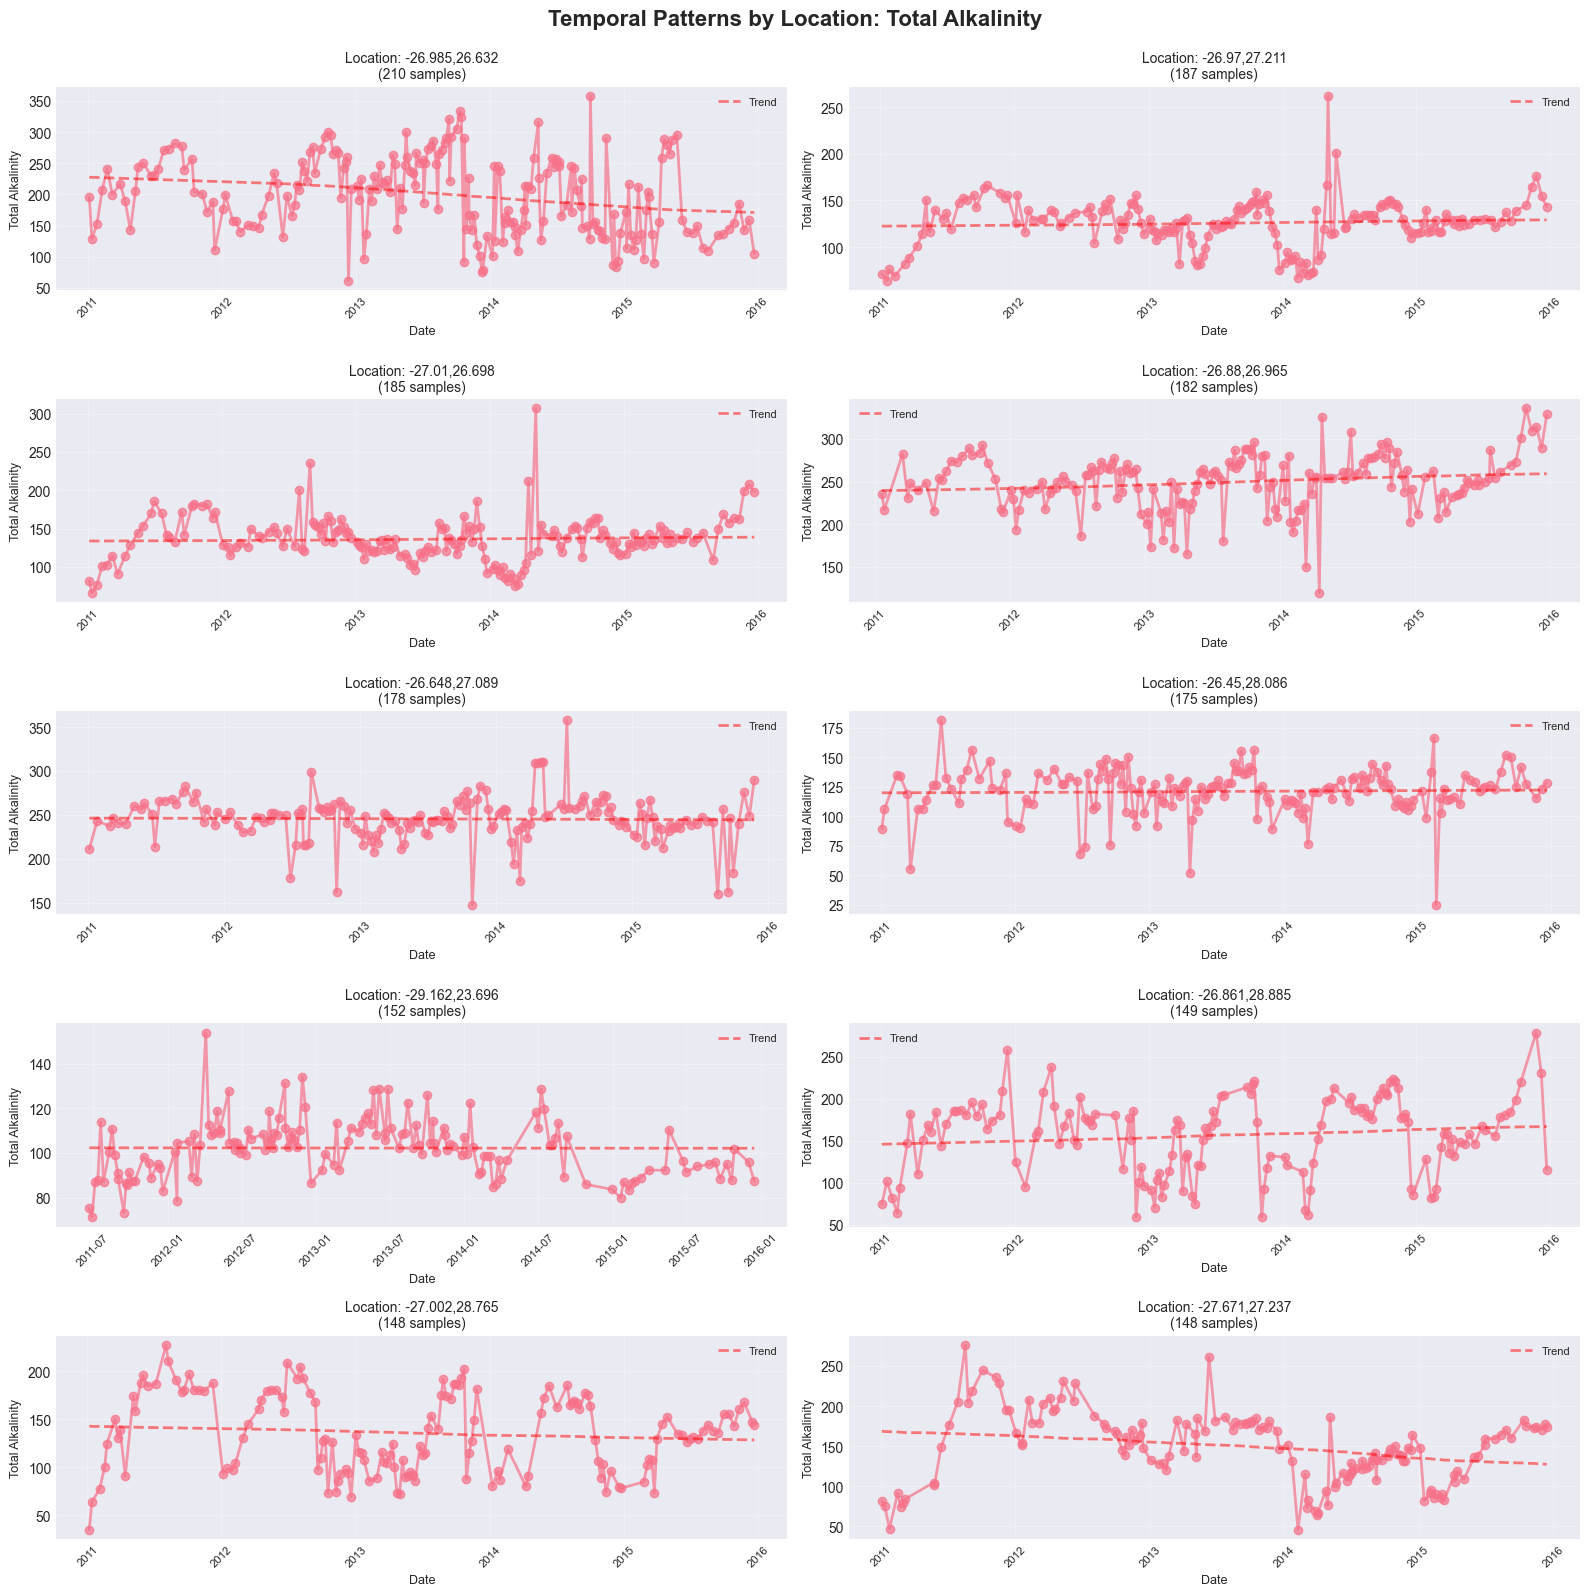

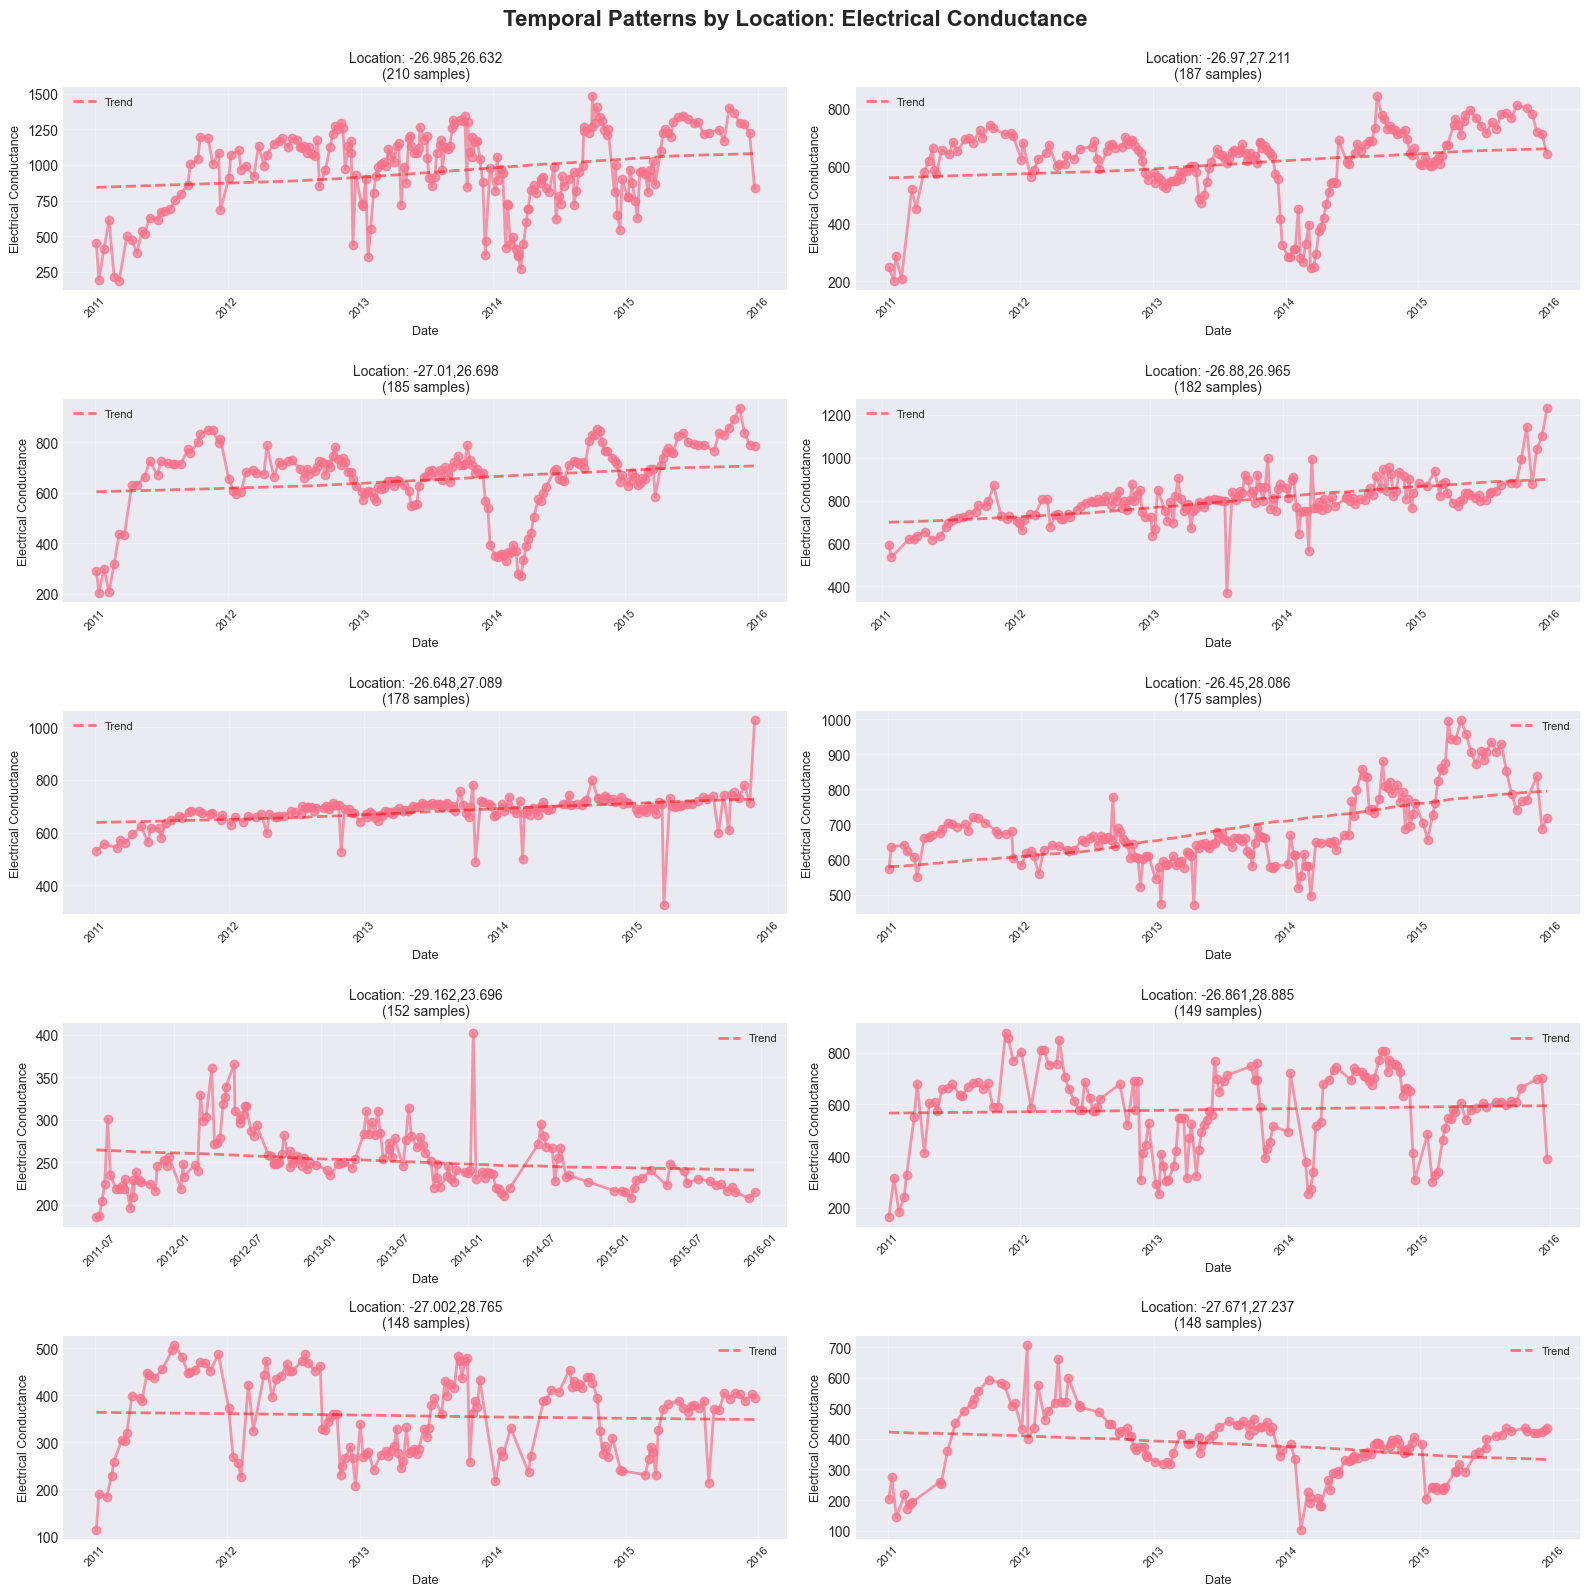

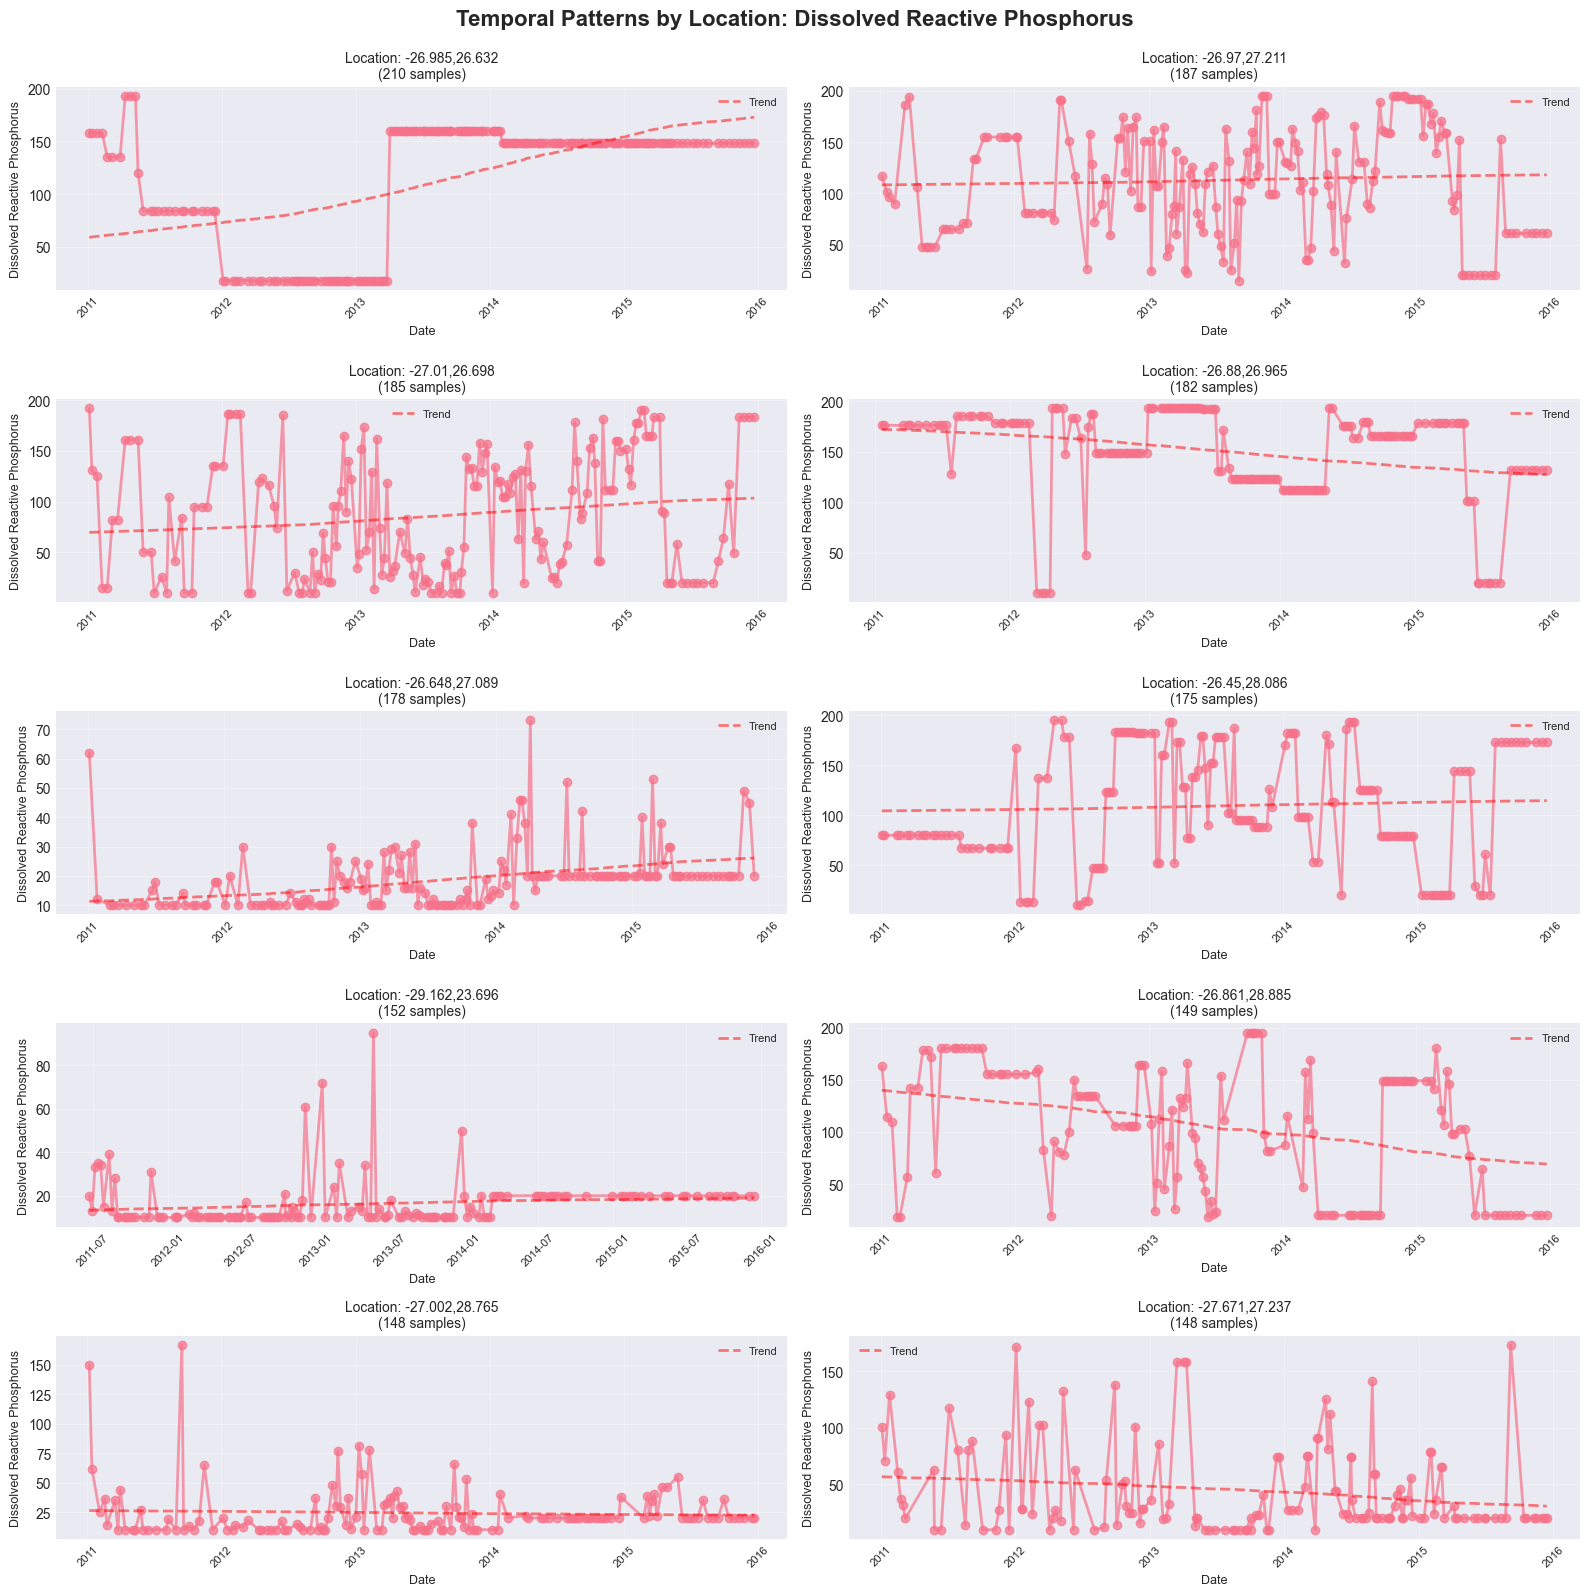

In [9]:
for param in available_params:
    fig, axes = plt.subplots(5, 2, figsize=(16, 16))
    axes = axes.flatten()
    
    for idx, location in enumerate(top_locations):
        loc_data = df[df['Location'] == location].sort_values('Date')
        
        axes[idx].plot(loc_data['Date'], loc_data[param], marker='o', 
                      linestyle='-', linewidth=2, markersize=6, alpha=0.7)
        axes[idx].set_title(f'Location: {location}\n({len(loc_data)} samples)', fontsize=10)
        axes[idx].set_xlabel('Date', fontsize=9)
        axes[idx].set_ylabel(param, fontsize=9)
        axes[idx].grid(True, alpha=0.3)
        axes[idx].tick_params(axis='x', rotation=45, labelsize=8)
        
        # Add trend line
        if len(loc_data) > 2:
            z = np.polyfit(range(len(loc_data)), loc_data[param], 1)
            p = np.poly1d(z)
            axes[idx].plot(loc_data['Date'], p(range(len(loc_data))), 
                          "r--", alpha=0.5, linewidth=2, label='Trend')
            axes[idx].legend(fontsize=8)
    
    fig.suptitle(f'Temporal Patterns by Location: {param}', fontsize=16, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.savefig(f'location_timeseries_{param.replace(" ", "_")}.png', dpi=300, bbox_inches='tight')
    plt.show()

### 4.2 Location-Specific Variability

In [11]:
# Calculate variability metrics per location
print("\n" + "="*80)
print("LOCATION-SPECIFIC TEMPORAL VARIABILITY")
print("="*80)

location_variability = []

for location in top_locations:
    loc_data = df[df['Location'] == location]
    
    if len(loc_data) > 1:
        row = {'Location': location}
        
        for param in available_params:
            values = loc_data[param].dropna()
            if len(values) > 1:
                row[f'{param}_mean'] = values.mean()
                row[f'{param}_std'] = values.std()
                row[f'{param}_cv'] = (values.std() / values.mean()) * 100
                row[f'{param}_range'] = values.max() - values.min()
        
        location_variability.append(row)

loc_var_df = pd.DataFrame(location_variability)
print("\nLocation Variability Summary:")
print(loc_var_df.to_string())

# Average CV across locations
print("\n" + "="*80)
print("Average Coefficient of Variation by Parameter (across top locations):")
print("="*80)
for param in available_params:
    cv_col = f'{param}_cv'
    if cv_col in loc_var_df.columns:
        avg_cv = loc_var_df[cv_col].mean()
        print(f"\n{param}: {avg_cv:.2f}%")
        
        if avg_cv > 50:
            print(f"   ⚠️  VERY HIGH variability at individual locations!")
            print(f"   → Strong temporal changes within locations require frequent imaging")
        elif avg_cv > 30:
            print(f"   ⚡ HIGH variability at individual locations")
            print(f"   → Significant temporal changes suggest multiple images per year")
        else:
            print(f"   ✓ Moderate variability at individual locations")
            print(f"   → Temporal changes are relatively stable")


LOCATION-SPECIFIC TEMPORAL VARIABILITY

Location Variability Summary:
         Location  Total Alkalinity_mean  Total Alkalinity_std  Total Alkalinity_cv  Total Alkalinity_range  Electrical Conductance_mean  Electrical Conductance_std  Electrical Conductance_cv  Electrical Conductance_range  Dissolved Reactive Phosphorus_mean  Dissolved Reactive Phosphorus_std  Dissolved Reactive Phosphorus_cv  Dissolved Reactive Phosphorus_range
0  -26.985,26.632             199.390231             61.476913            30.832460                 296.210                   961.196619                  277.478732                  28.868051                       1294.90                          115.790476                          58.013230                         50.101901                                175.0
1   -26.97,27.211             125.780556             25.467182            20.247312                 198.425                   609.899893                  128.897193                  21.134156          

## 5. Time Gap Analysis

Analyze the time gaps between consecutive measurements at the same location.


Time Gap Statistics (between consecutive measurements at same location):
count    9157.000000
mean       29.185869
std        41.558826
min         1.000000
25%        13.000000
50%        22.000000
75%        29.000000
max       782.000000
Name: Gap_Days, dtype: float64


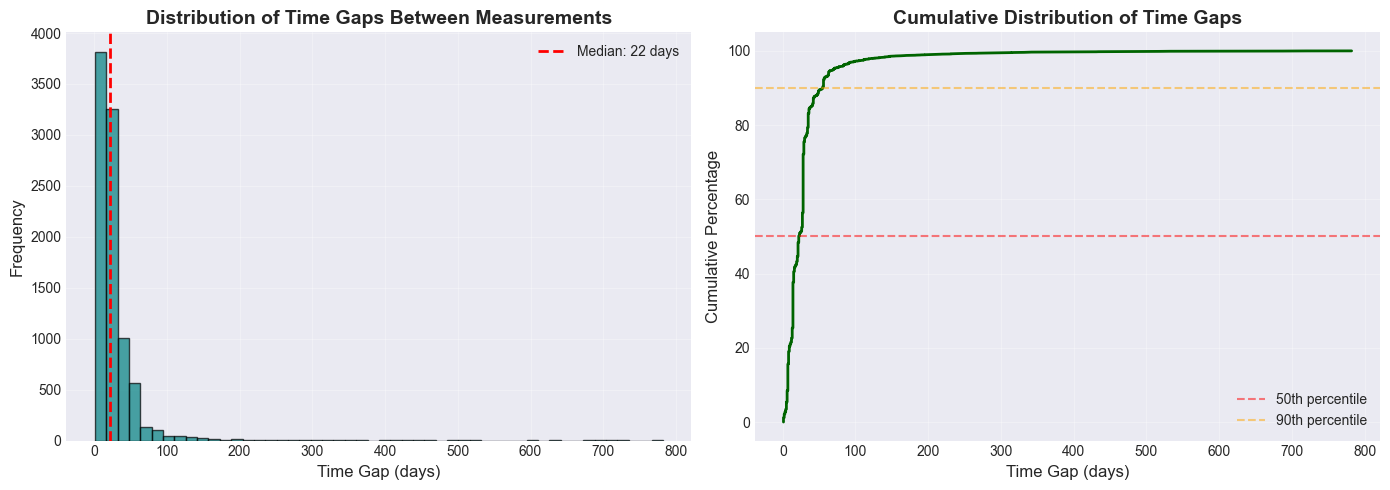


Median gap: 22 days (0.7 months)
90th percentile gap: 55 days (1.8 months)


In [12]:
time_gaps = []

for location in df['Location'].unique():
    loc_data = df[df['Location'] == location].sort_values('Date')
    
    if len(loc_data) > 1:
        dates = loc_data['Date'].values
        for i in range(1, len(dates)):
            gap_days = (pd.Timestamp(dates[i]) - pd.Timestamp(dates[i-1])).days
            time_gaps.append({
                'Location': location,
                'Gap_Days': gap_days,
                'Gap_Months': gap_days / 30.44,
                'Gap_Years': gap_days / 365.25
            })

gaps_df = pd.DataFrame(time_gaps)

if len(gaps_df) > 0:
    print("\nTime Gap Statistics (between consecutive measurements at same location):")
    print(gaps_df['Gap_Days'].describe())
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Distribution of gaps
    axes[0].hist(gaps_df['Gap_Days'], bins=50, color='teal', alpha=0.7, edgecolor='black')
    axes[0].axvline(gaps_df['Gap_Days'].median(), color='red', linestyle='--', 
                   linewidth=2, label=f'Median: {gaps_df["Gap_Days"].median():.0f} days')
    axes[0].set_xlabel('Time Gap (days)', fontsize=12)
    axes[0].set_ylabel('Frequency', fontsize=12)
    axes[0].set_title('Distribution of Time Gaps Between Measurements', fontsize=14, fontweight='bold')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Cumulative distribution
    sorted_gaps = np.sort(gaps_df['Gap_Days'])
    cumulative = np.arange(1, len(sorted_gaps) + 1) / len(sorted_gaps) * 100
    axes[1].plot(sorted_gaps, cumulative, linewidth=2, color='darkgreen')
    axes[1].axhline(50, color='red', linestyle='--', alpha=0.5, label='50th percentile')
    axes[1].axhline(90, color='orange', linestyle='--', alpha=0.5, label='90th percentile')
    axes[1].set_xlabel('Time Gap (days)', fontsize=12)
    axes[1].set_ylabel('Cumulative Percentage', fontsize=12)
    axes[1].set_title('Cumulative Distribution of Time Gaps', fontsize=14, fontweight='bold')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('time_gap_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\nMedian gap: {gaps_df['Gap_Days'].median():.0f} days ({gaps_df['Gap_Months'].median():.1f} months)")
    print(f"90th percentile gap: {gaps_df['Gap_Days'].quantile(0.9):.0f} days ({gaps_df['Gap_Months'].quantile(0.9):.1f} months)")

## 6. Change Rate Analysis

Calculate the rate of change in water quality parameters over time.

In [13]:
change_rates = []

for location in top_locations:
    loc_data = df[df['Location'] == location].sort_values('Date')
    
    if len(loc_data) > 1:
        for param in available_params:
            values = loc_data[['Date', param]].dropna()
            
            if len(values) > 1:
                for i in range(1, len(values)):
                    time_diff = (values.iloc[i]['Date'] - values.iloc[i-1]['Date']).days
                    value_diff = abs(values.iloc[i][param] - values.iloc[i-1][param])
                    
                    if time_diff > 0:
                        change_rates.append({
                            'Location': location,
                            'Parameter': param,
                            'Time_Diff_Days': time_diff,
                            'Value_Change': value_diff,
                            'Change_Rate_Per_Day': value_diff / time_diff,
                            'Change_Rate_Per_Month': (value_diff / time_diff) * 30.44,
                            'Percent_Change': (value_diff / values.iloc[i-1][param]) * 100 if values.iloc[i-1][param] != 0 else 0
                        })

changes_df = pd.DataFrame(change_rates)

if len(changes_df) > 0:
    print("\n" + "="*80)
    print("CHANGE RATE ANALYSIS")
    print("="*80)
    
    for param in available_params:
        param_changes = changes_df[changes_df['Parameter'] == param]
        
        if len(param_changes) > 0:
            print(f"\n{param}:")
            print(f"  Median change per month: {param_changes['Change_Rate_Per_Month'].median():.2f}")
            print(f"  90th percentile change per month: {param_changes['Change_Rate_Per_Month'].quantile(0.9):.2f}")
            print(f"  Median percent change between measurements: {param_changes['Percent_Change'].median():.1f}%")
            print(f"  90th percentile percent change: {param_changes['Percent_Change'].quantile(0.9):.1f}%")
            
            # Filter by time gaps
            short_term = param_changes[param_changes['Time_Diff_Days'] <= 90]  # Within 3 months
            long_term = param_changes[param_changes['Time_Diff_Days'] > 90]     # More than 3 months
            
            if len(short_term) > 0:
                print(f"\n  Short-term changes (≤3 months):")
                print(f"    Median percent change: {short_term['Percent_Change'].median():.1f}%")
            
            if len(long_term) > 0:
                print(f"  Long-term changes (>3 months):")
                print(f"    Median percent change: {long_term['Percent_Change'].median():.1f}%")


CHANGE RATE ANALYSIS

Total Alkalinity:
  Median change per month: 37.93
  90th percentile change per month: 183.40
  Median percent change between measurements: 7.6%
  90th percentile percent change: 31.9%

  Short-term changes (≤3 months):
    Median percent change: 7.6%

Electrical Conductance:
  Median change per month: 82.62
  90th percentile change per month: 457.67
  Median percent change between measurements: 4.0%
  90th percentile percent change: 21.9%

  Short-term changes (≤3 months):
    Median percent change: 4.0%

Dissolved Reactive Phosphorus:
  Median change per month: 0.00
  90th percentile change per month: 196.02
  Median percent change between measurements: 0.0%
  90th percentile percent change: 88.6%

  Short-term changes (≤3 months):
    Median percent change: 0.0%


## 7. Recommendations for Landsat Image Granularity

In [14]:
print("\n" + "="*80)
print("RECOMMENDATIONS FOR LANDSAT IMAGE COLLECTION FREQUENCY")
print("="*80)

print("\n📊 Summary of Findings:")
print("-" * 80)

# 1. Temporal coverage
print(f"\n1. TEMPORAL COVERAGE:")
print(f"   - Dataset spans {df['Year'].nunique()} years ({df['Date'].min().year}-{df['Date'].max().year})")
print(f"   - Average {unique_dates_per_year.mean():.0f} unique sampling dates per year")
print(f"   - Median time gap between measurements: {gaps_df['Gap_Days'].median():.0f} days")

# 2. Variability analysis
print(f"\n2. VARIABILITY PATTERNS:")
for param in available_params:
    # Calculate metrics
    yearly_means = df.groupby('Year')[param].mean()
    inter_annual_cv = (yearly_means.std() / yearly_means.mean()) * 100
    
    intra_annual_stds = []
    for year in df['Year'].unique():
        year_data = df[df['Year'] == year][param]
        if len(year_data) > 1:
            intra_annual_stds.append(year_data.std())
    intra_annual_cv = (np.mean(intra_annual_stds) / yearly_means.mean()) * 100
    
    print(f"\n   {param}:")
    print(f"     - Inter-annual CV: {inter_annual_cv:.1f}%")
    print(f"     - Intra-annual CV: {intra_annual_cv:.1f}%")
    print(f"     - Ratio (Intra/Inter): {intra_annual_cv/inter_annual_cv:.2f}")

# 3. Recommendations
print("\n" + "="*80)
print("🎯 RECOMMENDATIONS:")
print("="*80)

# Calculate overall recommendation based on all parameters
high_variability_params = 0
moderate_variability_params = 0

for param in available_params:
    yearly_means = df.groupby('Year')[param].mean()
    inter_annual_cv = (yearly_means.std() / yearly_means.mean()) * 100
    
    intra_annual_stds = []
    for year in df['Year'].unique():
        year_data = df[df['Year'] == year][param]
        if len(year_data) > 1:
            intra_annual_stds.append(year_data.std())
    intra_annual_cv = (np.mean(intra_annual_stds) / yearly_means.mean()) * 100
    
    ratio = intra_annual_cv / inter_annual_cv if inter_annual_cv > 0 else 0
    
    if ratio > 1.5:
        high_variability_params += 1
    elif ratio > 0.75:
        moderate_variability_params += 1

if high_variability_params >= len(available_params) / 2:
    print("\n🔴 RECOMMENDATION: QUARTERLY IMAGING (4 images per year)")
    print("\nRationale:")
    print("  - High intra-annual variability detected in most parameters")
    print("  - Water quality changes significantly within a single year")
    print("  - Seasonal patterns show substantial variation")
    print("\nSuggested timing: One image per season (Spring, Summer, Autumn, Winter)")
    print("  - This captures seasonal dynamics")
    print("  - Provides good temporal resolution for modeling")
    print("  - Balances data quality with acquisition costs")
    
elif moderate_variability_params >= len(available_params) / 2:
    print("\n🟡 RECOMMENDATION: SEMI-ANNUAL IMAGING (2-3 images per year)")
    print("\nRationale:")
    print("  - Moderate intra-annual variability detected")
    print("  - Some seasonal patterns present")
    print("  - Balance between temporal detail and resource efficiency")
    print("\nSuggested timing:")
    print("  - Minimum: Dry season (Winter) and Wet season (Summer)")
    print("  - Optimal: Add one transition season image (Spring or Autumn)")
    
else:
    print("\n🟢 RECOMMENDATION: ANNUAL IMAGING (1-2 images per year)")
    print("\nRationale:")
    print("  - Low intra-annual variability")
    print("  - Inter-annual changes are more significant than seasonal changes")
    print("  - Cost-effective approach suitable for long-term monitoring")
    print("\nSuggested timing:")
    print("  - Single image: Mid-year (around June-July) for consistency")
    print("  - Two images: Dry season (Winter) for stable conditions")

print("\n" + "="*80)
print("⚠️  ADDITIONAL CONSIDERATIONS:")
print("="*80)
print("\n  1. Cloud cover: Factor in typical cloud cover patterns for your region")
print("     - May need to target dry season for clearer imagery")
print("\n  2. Landsat revisit frequency: 16 days for single satellite, 8 days combined")
print("     - Can opportunistically collect additional images if available")
print("\n  3. Temporal windows: Use ±730 days as shown in your pipeline")
print("     - This provides flexibility for cloud-free image selection")
print("\n  4. Priority locations: Focus more frequent imaging on high-variability sites")
print(f"     - {len(top_locations)} locations show highest temporal variation")

print("\n" + "="*80)


RECOMMENDATIONS FOR LANDSAT IMAGE COLLECTION FREQUENCY

📊 Summary of Findings:
--------------------------------------------------------------------------------

1. TEMPORAL COVERAGE:
   - Dataset spans 5 years (2011-2015)
   - Average 273 unique sampling dates per year
   - Median time gap between measurements: 22 days

2. VARIABILITY PATTERNS:

   Total Alkalinity:
     - Inter-annual CV: 2.3%
     - Intra-annual CV: 62.8%
     - Ratio (Intra/Inter): 27.60

   Electrical Conductance:
     - Inter-annual CV: 6.1%
     - Intra-annual CV: 70.2%
     - Ratio (Intra/Inter): 11.55

   Dissolved Reactive Phosphorus:
     - Inter-annual CV: 9.8%
     - Intra-annual CV: 117.4%
     - Ratio (Intra/Inter): 11.93

🎯 RECOMMENDATIONS:

🔴 RECOMMENDATION: QUARTERLY IMAGING (4 images per year)

Rationale:
  - High intra-annual variability detected in most parameters
  - Water quality changes significantly within a single year
  - Seasonal patterns show substantial variation

Suggested timing: One ima

## 8. Export Summary Statistics

In [ ]:
# Create summary report
summary = {
    'Dataset': {
        'Total_Samples': len(df),
        'Unique_Locations': df['Location'].nunique(),
        'Unique_Dates': df['Date'].nunique(),
        'Date_Range': f"{df['Date'].min()} to {df['Date'].max()}",
        'Years_Covered': df['Year'].nunique()
    }
}

for param in available_params:
    summary[param] = {
        'Mean': df[param].mean(),
        'Std': df[param].std(),
        'CV': (df[param].std() / df[param].mean()) * 100,
        'Min': df[param].min(),
        'Max': df[param].max()
    }

# Save to JSON
import json
with open('temporal_analysis_summary.json', 'w') as f:
    json.dump(summary, f, indent=2, default=str)

print("\n✅ Analysis complete! Summary saved to 'temporal_analysis_summary.json'")
print("\n📊 Generated visualizations:")
print("   - temporal_distribution.png")
print("   - temporal_trends.png")
print("   - seasonal_patterns.png")
print("   - time_gap_analysis.png")
for param in available_params:
    print(f"   - location_timeseries_{param.replace(' ', '_')}.png")